In [19]:
#PACKS
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from pathlib import Path

#SETUP F
from sklearn.linear_model import LogisticRegression
from sklearn.kernel_approximation import RBFSampler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
    )
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS_MADRID    = {1: 'Pre-1960',  2: '1960-1984', 3: '1984-2004', 4: '2004-2024'}
CLASS_LABELS_AMSTERDAM = {1: 'Pre-1945',  2: '1945-1984', 3: '1984-2004', 4: '2004-2024'}
    
plt.rcParams['figure.dpi'] = 100
print("Setup complete.")


Setup complete.


In [20]:
#load preprocessed data
with open('/shared/mauro/Building_Age_Classification/data/preprocessed/preprocessed_data.pkl', 'rb') as f:
   data = pickle.load(f)
    
X_madrid    = data['X_madrid']
y_madrid    = data['y_madrid']
X_amsterdam = data['X_amsterdam']
y_amsterdam = data['y_amsterdam']
feature_names = data['feature_names']
pixel_ids_madrid    = data['pixel_ids_madrid']     # (N, 2)  px_key, py_key,
pixel_ids_amsterdam = data['pixel_ids_amsterdam']  # (N, 2)  px_key, py_key,
    
print(f'Madrid:    {X_madrid.shape}  ({len(np.unique(y_madrid))} classes)')
print(f'Amsterdam: {X_amsterdam.shape}  ({len(np.unique(y_amsterdam))} classes)')
print(f'Features:  {len(feature_names)}')
print()
for name, y, labels in [('Madrid', y_madrid, CLASS_LABELS_MADRID),
                        ('Amsterdam', y_amsterdam, CLASS_LABELS_AMSTERDAM)]:
    print(f'{name} class distribution:')
    for cls in sorted(np.unique(y)):
        n = (y == cls).sum()
        print(f'  Class {cls} ({labels[cls]}): {n:,}  ({n/len(y)*100:.1f}%)')
    print()

Madrid:    (76263, 60)  (4 classes)
Amsterdam: (25992, 60)  (4 classes)
Features:  60

Madrid class distribution:
  Class 1 (Pre-1960): 13,794  (18.1%)
  Class 2 (1960-1984): 27,152  (35.6%)
  Class 3 (1984-2004): 18,672  (24.5%)
  Class 4 (2004-2024): 16,645  (21.8%)

Amsterdam class distribution:
  Class 1 (Pre-1945): 7,568  (29.1%)
  Class 2 (1945-1984): 8,802  (33.9%)
  Class 3 (1984-2004): 6,745  (26.0%)
  Class 4 (2004-2024): 2,877  (11.1%)



In [32]:
# Cross-Validation on Madrid (Logistic Regression + RBF Sampler)
#Configuration: set cross-validation parameters 
N_FOLDS, N_REPEATS = 5, 5
total_fits  = N_FOLDS * N_REPEATS
rskf        = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=42)
   
all_f1      = []
oof_true    = []
oof_pred    = []
oof_proba   = []   # predict_proba output for each held-out pixel
oof_indices = []   # original row index of each held-out pixel
    
print(f'{N_FOLDS}-fold x {N_REPEATS}-repeat CV on Madrid with Logistic Regression + RBFSampler ({total_fits} model fits)')
print('-' * 70)
    
for fit_num, (tr_idx, val_idx) in enumerate(rskf.split(X_madrid, y_madrid), 1):
    X_tr, X_val = X_madrid[tr_idx], X_madrid[val_idx]
    y_tr, y_val = y_madrid[tr_idx], y_madrid[val_idx]
  
# Define pipeline with Scaling, RBF Feature Mapping, and Logistic Regression
    model_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('rbf_sampler', RBFSampler(gamma=0.1, n_components=500, random_state=42)),
        ('logistic', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, n_jobs=-1))
    ])

    model_pipeline.fit(X_tr, y_tr)
    y_pred  = model_pipeline.predict(X_val)
    y_proba = model_pipeline.predict_proba(X_val)

    oof_true.extend(y_val.tolist())
    oof_pred.extend(y_pred.tolist())
    oof_proba.extend(y_proba.tolist())
    oof_indices.extend(val_idx.tolist())

    f1 = f1_score(y_val, y_pred, average='macro')
    all_f1.append(f1)
    print(f'  Fit {fit_num:3d}/{total_fits}: macro-F1 = {f1:.4f}')

print('-' * 70)
print(f'  Mean macro F1: {np.mean(all_f1):.4f} +/- {np.std(all_f1):.4f}')

fold_f1     = all_f1
oof_true    = np.array(oof_true)
oof_pred    = np.array(oof_pred)
oof_proba   = np.array(oof_proba)
oof_indices = np.array(oof_indices)


5-fold x 5-repeat CV on Madrid with Logistic Regression + RBFSampler (25 model fits)
----------------------------------------------------------------------


/shared/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fit   1/25: macro-F1 = 0.5196


/shared/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fit   2/25: macro-F1 = 0.5278


/shared/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


... (41 outputs left out)

/shared/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fit  24/25: macro-F1 = 0.5158


/shared/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fit  25/25: macro-F1 = 0.5171
----------------------------------------------------------------------
  Mean macro F1: 0.5202 +/- 0.0042


In [33]:
# 100% of Madrid
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rbf_sampler', RBFSampler(gamma=0.1, n_components=500, random_state=42)),
    ('logistic', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

final_pipeline.fit(X_madrid, y_madrid)
print("Final model trained successfully on full Madrid dataset.")

Final model trained successfully on full Madrid dataset.


In [34]:
# Zero-Shot transfer Amsterdam
y_ams_pred = final_pipeline.predict(X_amsterdam)
zero_shot_f1 = f1_score(y_amsterdam, y_ams_pred, average='macro')

print("=" * 50)
print("         ZERO-SHOT EVALUATION (AMSTERDAM)         ")
print("=" * 50)
print(f"Zero-Shot Macro F1-Score: {zero_shot_f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_amsterdam, y_ams_pred, target_names=list(CLASS_LABELS_AMSTERDAM.values())))

         ZERO-SHOT EVALUATION (AMSTERDAM)         
Zero-Shot Macro F1-Score: 0.2361

Classification Report:
              precision    recall  f1-score   support

    Pre-1945       0.24      0.17      0.20      7568
   1945-1984       0.40      0.22      0.29      8802
   1984-2004       0.28      0.26      0.27      6745
   2004-2024       0.13      0.42      0.19      2877

    accuracy                           0.24     25992
   macro avg       0.26      0.27      0.24     25992
weighted avg       0.29      0.24      0.25     25992



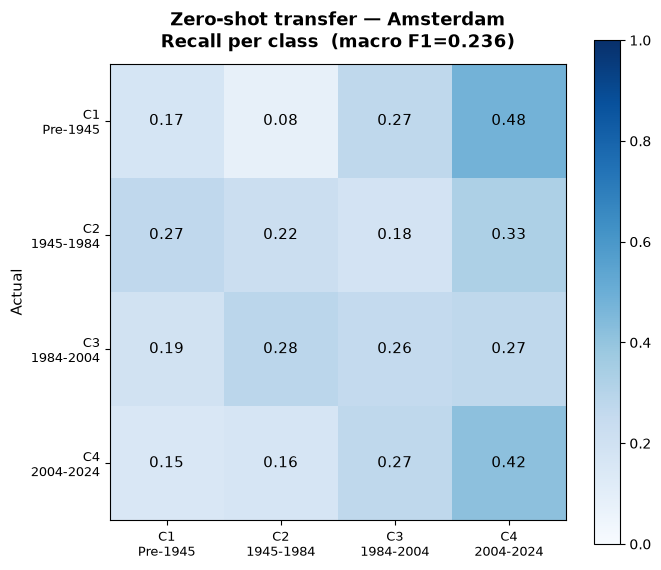

In [38]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

# Calcular a matriz normalizada por linha (Recall por classe)
cm = confusion_matrix(y_amsterdam, y_ams_pred, normalize='true')

fig, ax = plt.subplots(figsize=(7, 6))

# Plota a matriz com mapa de cores Blues e limite fixo de 0.0 a 1.0
im = ax.imshow(cm, cmap='Blues', vmin=0.0, vmax=1.0)
cbar = ax.figure.colorbar(im, ax=ax)

# Título com o Macro F1 real do seu modelo Zero-Shot
macro_f1 = f1_score(y_amsterdam, y_ams_pred, average='macro')
ax.set_title(f'Zero-shot transfer — Amsterdam\nRecall per class  (macro F1={macro_f1:.3f})', 
             fontsize=13, fontweight='bold', pad=12)

# Rótulos das classes idênticos à imagem (Código da classe + Período em nova linha)
labels = [
    'C1\nPre-1945',
    'C2\n1945-1984',
    'C3\n1984-2004',
    'C4\n2004-2024'
]

ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(labels, fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

ax.set_ylabel('Actual', fontsize=11)

# Preencher a matriz com as proporções formatadas com duas casas decimais (ex: 0.10)
for i in range(4):
    for j in range(4):
        val = cm[i, j]
        color = "white" if val > 0.5 else "black"
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontsize=11)

plt.tight_layout()
plt.show()

In [39]:
#Few-Shot Domain Transfer
from sklearn.model_selection import StratifiedShuffleSplit

# Lista com as amostras 
sample_sizes = [5, 10, 25, 50, 100, 200]
few_shot_results = {}

print("=" * 50)
print("         FEW-SHOT EVALUATION (AMSTERDAM)          ")
print("=" * 50)

for n_samples in sample_sizes:
    f1_scores = []
    # 5 iterações
    for seed in range(5):
        sss = StratifiedShuffleSplit(
            n_splits=1, 
            train_size=n_samples * len(np.unique(y_amsterdam)), 
            random_state=seed
        )
        for train_idx, test_idx in sss.split(X_amsterdam, y_amsterdam):
            X_sub, y_sub = X_amsterdam[train_idx], y_amsterdam[train_idx]
            X_test, y_test = X_amsterdam[test_idx], y_amsterdam[test_idx]

            few_shot_pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('rbf_sampler', RBFSampler(gamma=0.1, n_components=500, random_state=42)),
                ('logistic', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
            ])

            few_shot_pipeline.fit(X_sub, y_sub)
            preds = few_shot_pipeline.predict(X_test)
            f1_scores.append(f1_score(y_test, preds, average='macro'))

    mean_f1 = np.mean(f1_scores)
    few_shot_results[n_samples] = mean_f1
    print(f"N = {n_samples:3d} amostras/classe | Few-Shot Macro F1: {mean_f1:.4f}")

# Cálculo do Average F1 e Peak F1
avg_f1 = np.mean(list(few_shot_results.values()))
peak_f1 = np.max(list(few_shot_results.values()))

print("-" * 50)
print(f"Average F1 (média entre N=5 e N=200): {avg_f1:.4f}")
print(f"Peak F1    (máximo atingido)        : {peak_f1:.4f}")
print("=" * 50)

         FEW-SHOT EVALUATION (AMSTERDAM)          
N =   5 amostras/classe | Few-Shot Macro F1: 0.3581
N =  10 amostras/classe | Few-Shot Macro F1: 0.4194
N =  25 amostras/classe | Few-Shot Macro F1: 0.4946
N =  50 amostras/classe | Few-Shot Macro F1: 0.5322
N = 100 amostras/classe | Few-Shot Macro F1: 0.5617
N = 200 amostras/classe | Few-Shot Macro F1: 0.5878
--------------------------------------------------
Average F1 (média entre N=5 e N=200): 0.4923
Peak F1    (máximo atingido)        : 0.5878


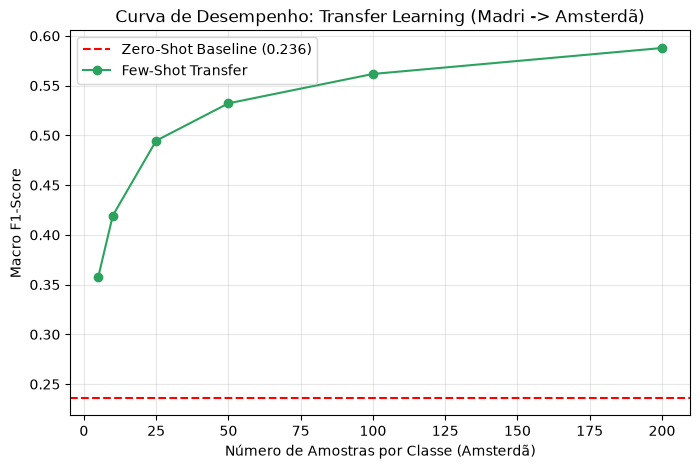

In [40]:
plt.figure(figsize=(8, 5))
plt.axhline(zero_shot_f1, color='red', linestyle='--', label=f'Zero-Shot Baseline ({zero_shot_f1:.3f})')
plt.plot(list(few_shot_results.keys()), list(few_shot_results.values()), marker='o', color='#2ca25f', label='Few-Shot Transfer')
plt.xlabel('Número de Amostras por Classe (Amsterdã)')
plt.ylabel('Macro F1-Score')
plt.title('Curva de Desempenho: Transfer Learning (Madri -> Amsterdã)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

def create_spatial_grid(pixel_ids, values, fill_value=np.nan):
    """Reconstrói a grelha 2D a partir dos IDs dos pixéis (px_key, py_key)."""
    px = pixel_ids[:, 0].astype(int)
    py = pixel_ids[:, 1].astype(int)
    
    min_x, max_x = px.min(), px.max()
    min_y, max_y = py.min(), py.max()
    
    width = max_x - min_x + 1
    height = max_y - min_y + 1
    
    if values.ndim == 1:
        grid = np.full((height, width), fill_value, dtype=values.dtype)
        grid[py - min_y, px - min_x] = values
    else:
        channels = values.shape[1]
        grid = np.full((height, width, channels), fill_value, dtype=values.dtype)
        grid[py - min_y, px - min_x, :] = values
        
    return grid, (min_x, max_x, min_y, max_y)


def plot_set1_class_maps_varied(pixel_ids, proba, y_true, title_prefix='Amsterdam zero-shot'):
    """Set 1 — Class Colour Maps com Cores Alternativas (Teal, Amber, Magenta)"""
    
    # Mistura de probabilidades para RGB alternativo
    # R: C2 (Coral), G: C3 (Teal), B: C4 (Purple/Indigo)
    rgb_vals = proba[:, [1, 2, 3]] 
    rgb_grid, _ = create_spatial_grid(pixel_ids, rgb_vals, fill_value=0.55) # Fundo cinza suave
    
    mask_grid, _ = create_spatial_grid(pixel_ids, np.ones(len(pixel_ids)), fill_value=0)
    for c in range(3):
        rgb_grid[:, :, c] = np.where(mask_grid == 1, rgb_grid[:, :, c], 0.55)

    # Paleta para as classes reais:
    # C1: Azul Grafite (#2b5c8f), C2: Laranja Terracota (#d95f02), C3: Verde Menta (#1b9e77), C4: Roxo Violeta (#7570b3)
    classes_grid, _ = create_spatial_grid(pixel_ids, y_true, fill_value=0)
    
    cmap_classes = ListedColormap(['#8d99ae', '#2b5c8f', '#d95f02', '#1b9e77', '#7570b3'])
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Set 1 — class colour maps  (grey = no building pixel)', fontsize=14, fontweight='bold', y=0.98)

    # Subplot 1: Predicted Probabilities
    axes[0].imshow(rgb_grid, origin='lower')
    axes[0].set_title(f'{title_prefix}\nPredicted probabilities  (R=$p_2$, G=$p_3$, B=$p_4$)', fontsize=11)
    axes[0].axis('off')

    # Subplot 2: Actual Classes
    axes[1].imshow(classes_grid, cmap=cmap_classes, vmin=0, vmax=4, origin='lower')
    axes[1].set_title(f'{title_prefix}\nActual classes', fontsize=11)
    axes[1].axis('off')

    legend_elements = [
        Patch(facecolor='#2b5c8f', label='C1'),
        Patch(facecolor='#d95f02', label='C2'),
        Patch(facecolor='#1b9e77', label='C3'),
        Patch(facecolor='#7570b3', label='C4'),
        Patch(facecolor='#8d99ae', label='No building')
    ]
    axes[1].legend(handles=legend_elements, loc='lower right', frameon=True)

    plt.tight_layout()
    plt.show()


def plot_set2_uncertainty_maps_varied(pixel_ids, proba, y_true, title_prefix='Amsterdam zero-shot'):
    """Set 2 — Uncertainty Maps utilizando o colormap 'inferno' em vez de 'hot'"""
    
    eps = 1e-12
    proba_clean = np.clip(proba, eps, 1 - eps)
    entropy = -np.sum(proba_clean * np.log2(proba_clean), axis=1)
    
    y_true_idx = y_true.astype(int) - 1
    p_true = proba_clean[np.arange(len(y_true)), y_true_idx]
    kl_div = -np.log2(p_true)

    entropy_grid, _ = create_spatial_grid(pixel_ids, entropy, fill_value=np.nan)
    kl_grid, _ = create_spatial_grid(pixel_ids, kl_div, fill_value=np.nan)

    # Usando paleta'inferno_r' (invertido: claro = certo, escuro = incerto)
    cmap_inferno = plt.cm.inferno_r.copy()
    cmap_inferno.set_bad(color='#8d99ae') # Cinzento neutro para fundo

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Set 2 — uncertainty & accuracy maps  (grey=no building  |  bright=good, dark=bad)', fontsize=14, fontweight='bold', y=0.98)

    # Subplot 1: Shannon Entropy
    im1 = axes[0].imshow(entropy_grid, cmap=cmap_inferno, vmin=0.0, vmax=2.0, origin='lower')
    axes[0].set_title(f'{title_prefix}\nShannon entropy  (bright=certain, dark=uncertain  |  max=2 bits)', fontsize=11)
    axes[0].axis('off')
    fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

    # Subplot 2: KL Divergence
    im2 = axes[1].imshow(kl_grid, cmap=cmap_inferno, vmin=0.0, vmax=2.0, origin='lower')
    axes[1].set_title(f'{title_prefix}\nKL from true class = $-\\log_2 p_{{true}}$ (bits)\nbright=accurate, dark=inaccurate', fontsize=11)
    axes[1].axis('off')
    fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


def plot_correct_incorrect_maps_varied(pixel_ids, y_true, y_pred, title_prefix='Amsterdam zero-shot'):
    """Correct / Incorrect Maps com combinação de Azul Cobalto / Magenta para erros"""
    
    is_correct = (y_true == y_pred).astype(int)
    grid_correct, _ = create_spatial_grid(pixel_ids, is_correct, fill_value=-1)
    
    class_correctness = np.where(y_true == y_pred, y_true, 5)
    grid_class_corr, _ = create_spatial_grid(pixel_ids, class_correctness, fill_value=0)

    # Cores: Acerto = Azul Escuro (#003049), Erro = Rosa Choque (#e63946)
    cmap_binary = ListedColormap(['#8d99ae', '#e63946', '#003049']) 
    
    # Detalhado por classe: C1-C4 em tons frios/quentes contrastantes, Erro = Laranja Vivo (#f77f00)
    cmap_detailed = ListedColormap(['#8d99ae', '#2b5c8f', '#d95f02', '#1b9e77', '#7570b3', '#f77f00'])

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Correct / incorrect pixel maps  (grey = no building pixel)', fontsize=14, fontweight='bold', y=0.98)

    # Subplot 1: Binary
    axes[0].imshow(grid_correct, cmap=cmap_binary, vmin=-1, vmax=1, origin='lower')
    axes[0].set_title(f'{title_prefix}\nCorrect vs incorrect', fontsize=11)
    axes[0].axis('off')
    
    leg1 = [
        Patch(facecolor='#003049', label='Correct'),
        Patch(facecolor='#e63946', label='Incorrect'),
        Patch(facecolor='#8d99ae', label='No building')
    ]
    axes[0].legend(handles=leg1, loc='lower right', frameon=True)

    # Subplot 2: Detailed
    axes[1].imshow(grid_class_corr, cmap=cmap_detailed, vmin=0, vmax=5, origin='lower')
    axes[1].set_title(f'{title_prefix}\nCorrect class / incorrect', fontsize=11)
    axes[1].axis('off')

    leg2 = [
        Patch(facecolor='#2b5c8f', label='C1 correct'),
        Patch(facecolor='#d95f02', label='C2 correct'),
        Patch(facecolor='#1b9e77', label='C3 correct'),
        Patch(facecolor='#7570b3', label='C4 correct'),
        Patch(facecolor='#f77f00', label='Incorrect'),
        Patch(facecolor='#8d99ae', label='No building')
    ]
    axes[1].legend(handles=leg2, loc='lower right', frameon=True)

    plt.tight_layout()
    plt.show()